Test of implementation of 2D linear equation:

Discretized solution:

$$ u_{i, j} ^{n+1} = u_{i, j} ^{n} - \frac {c} {\Delta t} (\frac {u_{i, j} ^{n} - u_{i - 1, j} ^{n}} {\Delta x} +\frac {u_{i, j} ^{n} - u_{i, j - 1} ^{n}} {\Delta y} )$$

Initial conditions:

$$ u(x, y) = 
\begin{cases}
2, \text{for 0.5 <= x, y <= 1} \\
1, \text{for everywhere else}
\end{cases}  
$$

Boundary conditions:
$$ u = 1 \text{  for}
\begin{cases}
x = 0, 2\\
y = 0, 2
\end{cases}  
$$

In [84]:
import numpy as np
from matplotlib import pyplot as plt, cm

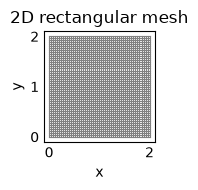

In [85]:
# initialize domain
domain = [(0, 2), (0, 2)]
nx = 51
ny = 51
c = 1

dx = (domain[0][1] - domain[0][0]) / (nx - 1)
dy = (domain[1][1] - domain[1][0]) / (ny - 1)

x = np.linspace(domain[0][0], domain[0][1], nx)
y = np.linspace(domain[1][0], domain[1][1], ny)


def create_rectangular_mesh(x, y):
    """
    Function that creates a 2D rectangular mesh based on a x-vector and a y-vector.
    
    Inputs:
    x - a numpy array representing the x domain discretization
    y - a numpy array representing the y domain discretization

    Outputs:
    mesh - a numpy 2x2 array containing tuples of coordinates of each mesh point
    """
    mesh = np.empty((nx, ny), dtype=object)

    for i in range(nx):
        for j in range(ny):
            mesh[i, j] = (x[i], y[j])

    return mesh

def plot_rectangular_mesh(rect_mesh):
    """
    Plot a 2D rectangular mesh.

    Parameters:
    rect_mesh - a 2D array of mesh points, where each point is an (x, y) tuple.

    Displays:
    A plot showing the mesh lines with equal scaling on both axes.
    """
    fig, ax = plt.subplots()

    for i in range(rect_mesh.shape[0]):
        ax.plot(
            [rect_mesh[i, j][0] for j in range(rect_mesh.shape[1])],
            [rect_mesh[i, j][1] for j in range(rect_mesh.shape[1])],
            color="gray",
            linewidth=0.8,
        )

    for j in range(rect_mesh.shape[1]):
        ax.plot(
            [rect_mesh[i, j][0] for i in range(rect_mesh.shape[0])],
            [rect_mesh[i, j][1] for i in range(rect_mesh.shape[0])],
            color="gray",
            linewidth=0.8,
        )

    ax.set_aspect("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title("2D rectangular mesh")
    fig.tight_layout()
    plt.show()

mesh = create_rectangular_mesh(x, y)

#visualize 2D mesh
plot_rectangular_mesh(mesh)


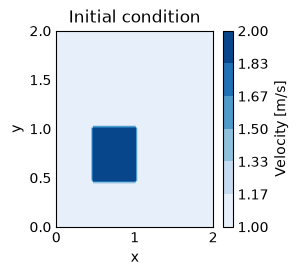

In [86]:
# Initial conditions
u = np.ones((nx, ny))
u[int(0.5 / dx):int(1 / dx) + 1, int(0.5 / dy):int(1 / dy) + 1] = 2

# Visualize the initial condition in 3D
X, Y = np.meshgrid(x, y, indexing="ij")
fig, ax = plt.subplots()
levels = np.linspace(u.min(), u.max(), 7)
contour = ax.contourf(X, Y, u, levels = levels)
fig.colorbar(contour, ax=ax, label="Velocity [m/s]", format="%.2f")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Initial condition")
plt.show()

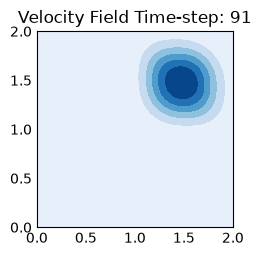

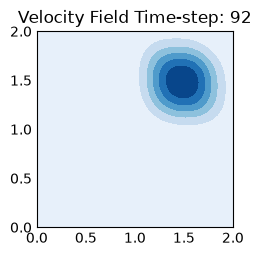

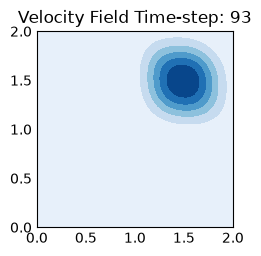

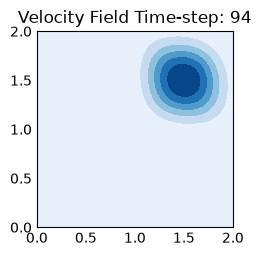

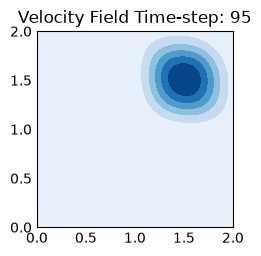

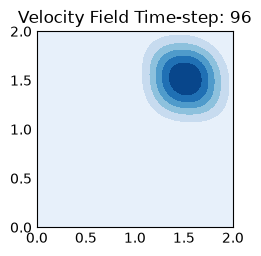

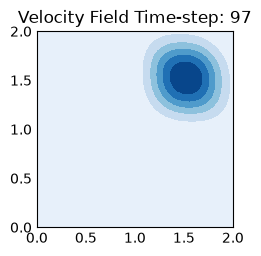

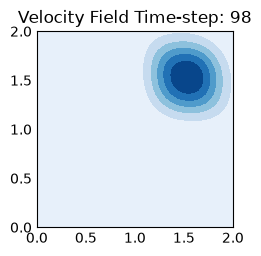

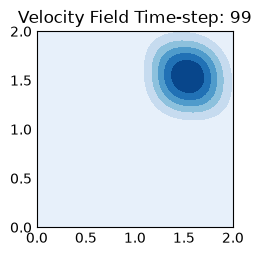

In [87]:
#iterations loop guaranteeing boundary conditions
sigma =.2
dt = dx * sigma
nt = 100

u = np.ones((nx, ny))
u[int(0.5 / dx):int(1 / dx) + 1, int(0.5 / dy):int(1 / dy) + 1] = 2

X, Y = np.meshgrid(x, y, indexing="ij")

for n in range(nt):
    un = u.copy()
    u[1:, 1:] = un[1:, 1:] - c*dt/dx*(un[1:, 1:] - un[:-1, 1:]) - c*dt/dy*(un[1:, 1:] - un[1:,:-1])
    u[0, :] = 1
    u[:, 0] = 1
    # u[-1, :] = 1
    # u[:, -1] = 1

    if nt - n < 10:
        plt.style.use('_mpl-gallery-nogrid')
        levels = np.linspace(u.min(), u.max(), 7)
        fig, ax = plt.subplots()
        ax.contourf(X, Y, u, levels = levels)
        ax.set_title(f"Velocity Field Time-step: {n}")
        plt.show()

# fig = plt.figure(figsize = (11,7), dpi=100)
# ax = fig.add_subplot(111, projection='3d')
# # The '111' means a grid of 1 row and 1 column and this subplot is the first one.
# X, Y = np.meshgrid(x,y)
# surf = ax.plot_surface(X,Y,u,cmap=cm.viridis)    
    

In [88]:
def solver_2D_Linear_Convection(x, y, u0, c, dx, dt, nt) -> dict:
    """
    Solve the 2D linear convection equation using a forward-time,
    backward-space finite-difference scheme.

    Parameters
    ----------
    x : array-like of float, shape (nx,)
        Grid coordinates in the x direction.
    y : array-like of float, shape (ny,)
        Grid coordinates in the y direction.
    u0 : numpy.ndarray of float, shape (nx, ny)
        Initial solution values on the grid. Its shape must match the
        lengths of x and y.
    c : float
        Convection speed.
    dx : float
        Grid spacing in the x direction.
    dt : float
        Time step.
    nt : int
        Number of solution time levels to store, including the initial
        condition. Must be at least 1.

    Returns
    -------
    dict[float, numpy.ndarray]
        Maps each time value (starting at 0) to a copy of the solution
        array at that time. The solution arrays have shape (nx, ny).
        The boundaries u[0, :] and u[:, 0] are set to 1 at each step.

        Returns an empty dictionary if the shape of u0 is incompatible
        with x and y.
    """
    solution: dict = {}

    # Verify if shapes are compatible
    if not ((np.shape(u0)[0] == len(x)) and (np.shape(u0)[1] == len(y))):
        print("ERROR! SIZES NOT COMPATIBLE")
        return {}

    # Solve
    u = u0.copy()
    solution[0] = u.copy()

    for n in range(1, nt):
        un = u.copy()
        u[1:, 1:] = (
            un[1:, 1:]
            - c * dt / dx * (un[1:, 1:] - un[:-1, 1:])
            - c * dt / dy * (un[1:, 1:] - un[1:, :-1])
        )
        u[0, :] = 1
        u[:, 0] = 1

        t = n * dt
        solution[t] = u.copy()

    return solution

In [89]:
#use of defined function

# Initial conditions
u0 = np.ones((nx, ny))
u0[int(0.5 / dx):int(1 / dx) + 1, int(0.5 / dy):int(1 / dy) + 1] = 2

convection_solution = solver_2D_Linear_Convection(x, y, u0, 1, dx, dt, 100)

In [94]:
print(convection_solution.keys())

print(convection_solution[0.68])

dict_keys([0, 0.008, 0.016, 0.024, 0.032, 0.04, 0.048, 0.056, 0.064, 0.07200000000000001, 0.08, 0.088, 0.096, 0.10400000000000001, 0.112, 0.12, 0.128, 0.136, 0.14400000000000002, 0.152, 0.16, 0.168, 0.176, 0.184, 0.192, 0.2, 0.20800000000000002, 0.216, 0.224, 0.232, 0.24, 0.248, 0.256, 0.264, 0.272, 0.28, 0.28800000000000003, 0.296, 0.304, 0.312, 0.32, 0.328, 0.336, 0.34400000000000003, 0.352, 0.36, 0.368, 0.376, 0.384, 0.392, 0.4, 0.40800000000000003, 0.41600000000000004, 0.424, 0.432, 0.44, 0.448, 0.456, 0.464, 0.47200000000000003, 0.48, 0.488, 0.496, 0.504, 0.512, 0.52, 0.528, 0.536, 0.544, 0.552, 0.56, 0.5680000000000001, 0.5760000000000001, 0.584, 0.592, 0.6, 0.608, 0.616, 0.624, 0.632, 0.64, 0.648, 0.656, 0.664, 0.672, 0.68, 0.6880000000000001, 0.6960000000000001, 0.704, 0.712, 0.72, 0.728, 0.736, 0.744, 0.752, 0.76, 0.768, 0.776, 0.784, 0.792])
[[1.         1.         1.         ... 1.         1.         1.        ]
 [1.         1.         1.         ... 1.         1.         1.